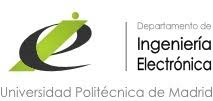

<div align="center">


# **Reconocimiento facial de emociones (Facial Emotion Recognition)**
### **Versión del 7 de Septiembre de 2026**
---
---

</div>

Facial emotion expression recognition can provide valuable information in a wide range of contexts, including healthcare, education, human–computer interaction, and social robotics. Human facial expressions are a key non-verbal communication channel, often conveying affective states such as happiness, sadness, anger, fear, surprise, disgust, or neutrality. Automatic analysis of these expressions can help systems better interpret a person’s emotional condition and respond in a more adaptive and human-centred manner.

In clinical and wellbeing-related settings, facial emotion recognition may support the observation of changes in emotional responsiveness associated with conditions such as depression, anxiety, autism spectrum disorder, dementia, or neurological disorders. For example, reduced facial expressiveness, atypical emotional reactions, or difficulties recognising and producing expressions may provide useful complementary indicators for clinicians. Such systems should support—not replace—professional assessment, since emotions are complex, context-dependent, and expressed differently across individuals and cultures.

Facial emotion expression recognition typically combines face detection, facial landmark localisation, feature extraction, and machine-learning or deep-learning models. Cameras capture images or video sequences, after which algorithms identify relevant facial regions and landmarks, including the eyes, eyebrows, nose, mouth, and jawline. Variations in the position, shape, and movement of these features can then be analysed to estimate facial action patterns or emotional-expression categories in real time.

This technology has several relevant applications:

1. Healthcare and psychological assessment: Facial expression analysis can assist clinicians and researchers in monitoring emotional states, evaluating patient engagement, and detecting changes in affective behaviour over time.

2. Education and learning analytics: In digital learning environments, emotion recognition may help identify signs of confusion, frustration, boredom, or engagement. This information can support the adaptation of instructional materials or provide teachers with feedback about student interaction.

3. Human–computer interaction: Emotion-aware systems can make interactions with computers, virtual assistants, and smart devices more natural. For instance, an interface may modify its responses when it detects that a user appears confused or frustrated.

4. Social robotics and assistive technologies: Robots designed for care, companionship, or customer interaction can use facial emotion recognition to adapt their communication style and provide more appropriate responses to users.

5. Driver monitoring and safety: In vehicles, facial analysis may contribute to detecting fatigue, stress, distraction, or reduced attention, potentially supporting safer driving environments.

6. Market research and user-experience evaluation: Facial expressions can be analysed to study users’ reactions to products, advertisements, digital interfaces, or entertainment content.

To operate effectively in real time, facial emotion recognition systems require robust computer-vision and artificial-intelligence techniques capable of handling variations in lighting, head pose, occlusions, image quality, age, ethnicity, and individual expressiveness. Equally important are privacy, informed consent, transparency, and bias mitigation, as emotional data are sensitive and automated inferences can be uncertain. When designed and used responsibly, facial emotion expression recognition can offer meaningful support for understanding affective behaviour and creating more responsive intelligent systems.

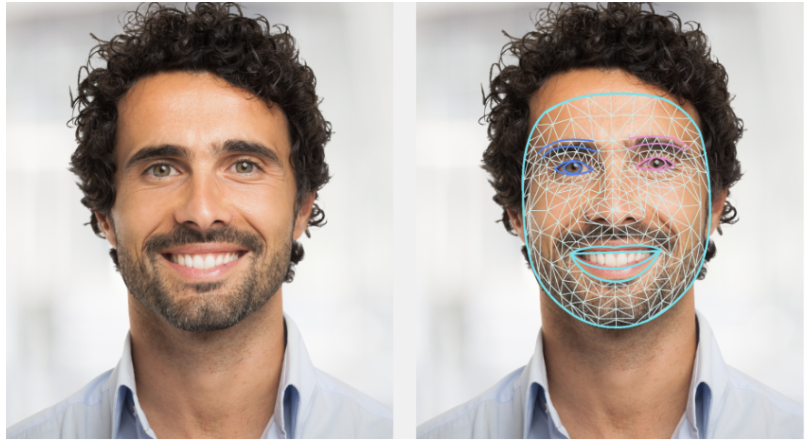





**Data Analysis**

For the purpose of our analysis, we will be working with the landmarks extracted from the images. These landmarks provide information about the position and orientation.
Our goal will be to develop models or perform analysis to discern between the different behaviours based on the extracted landmarks. This could involve tasks such as emotion recognition, activity classification...


**Summary**

This practice is dedicated to the familiarization with the tools introduced during the course, more specifically, to mediapipe and Tensorflow.

The main concepts that we will work are:

1. Firstly, we will extract, interpret, and work with landmarks from different images. This involves extracting the relevant features or points of interest from the images and representing them as landmarks.
2. Secondly, we will train multiple models using the extracted landmarks. We will analyze the performance and predictions of each model, evaluating metrics such as accuracy, precision, recall, and F1-score. This step allows us to assess how well each model performs in recognizing and classifying gestures based on the landmarks
3. Thirdly, we will compare the performance of the different models and make any necessary adjustments or refinements. This may involve fine-tuning the models' hyperparameters, adding more data to improve generalization, or applying techniques to address specific challenges or limitations. The goal is to select the most suitable model that achieves the best overall performance in classifying the gestures based on the landmarks.

# Workspace preparation

## Google Drive personal folder mount
The project will be executed in a folder that the student must upload to Google Drive with the database. The files generated throughout the practice, such as models, predictions, etc., will be saved in this folder


In [9]:
# Connect to Drive
from google.colab import drive
drive.mount('/content/drive')

# Clonar el repositorio sin descargar todo el contenido
!git clone --filter=blob:none --no-checkout https://github.com/efhes/IE-workspace.git

%cd IE-workspace

# Activar sparse checkout
!git sparse-checkout init --cone

# Seleccionar las carpetas necesarias
!git sparse-checkout set FER_mediapipe common

# Descargar solo esas carpetas
!git checkout

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Cloning into 'IE-workspace'...
remote: Enumerating objects: 546, done.
remote: Counting objects: 100% (50/50), done.
remote: Compressing objects: 100% (38/38), done.
remote: Total 546 (delta 14), reused 38 (delta 10), pack-reused 496 (from 2)
Receiving objects: 100% (546/546), 84.86 KiB | 1.35 MiB/s, done.
Resolving deltas: 100% (209/209), done.
/content/IE-workspace/IE-workspace
remote: Enumerating objects: 64, done.
remote: Counting objects: 100% (26/26), done.
remote: Compressing objects: 100% (26/26), done.
remote: Total 64 (delta 2), reused 12 (delta 0), pack-reused 38 (from 2)
Receiving objects: 100% (64/64), 31.81 MiB | 17.00 MiB/s, done.
Resolving deltas: 100% (5/5), done.
Updating files: 100% (65/65), done.
Your branch is up to date with 'origin/master'.


## MediaPipe installation

Let's start with installing MediaPipe.

In [10]:
!pip install -q mediapipe

## Import required libraries
In this section, we will download and import all the neccessary packages for running the experiments.

Among the packages and libraries installed, the most important are:

* **Mediapipe** is an open-source framework developed by Google that provides a comprehensive pipeline for building multimodal (audio, video, and sensor) applications. It offers a wide range of pre-built and customizable machine learning models and processing modules, making it easier to develop complex multimedia applications.
* **pandas**: Python library that lets deal with csv and convert them to a DataFrame, type of data organization in a kind of table format.
* **tensorflow**: Open source software library for numerical computation using data-flow graphs and for implementing and training artificial neural networks.
* **numpy**: This Python library is oriented to make numeric operactions, algebra and mathematic analysis.
* **matplotlib**: This Python library contains graphic plot functions, similr to the resources available in Matlab for showing graphs.

In [11]:
!pip install mediapipe opencv-python tensorflow wandb scikit-learn pandas keras matplotlib seaborn tqdm

### Path definition and libs import checking

In [13]:
import sys

sys.path.append('/content/IE-workspace/FER_mediapipe/src/')
sys.path.append("/content/IE-workspace/common/")

import landmarks_utils
print("Recursos de landmarks_utils:", dir(landmarks_utils)) # To check if it works

import config
print("Recursos de common:", dir(config)) # To check if it works

Recursos de landmarks_utils: ['ArrangeInputDataForNetwork', 'FlattenFaceLandmarks', 'GetFaceLandmarksFromImages', 'GetFaceLandmarksListFromDetectionResult', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__spec__', 'create_numpy_with_feats_and_csv_with_just_labels', 'cv2', 'draw_landmarks_on_image', 'drawing_styles', 'drawing_utils', 'extract_classes_list_from_folders', 'face_get_XYZ', 'hand_get_XYZ', 'load_individual_class_features_and_create_labeled_csv_dataset', 'math', 'mp', 'normalize_L0', 'normalize_all_samples', 'normalize_all_samples_L0', 'normalize_all_samples_rotation', 'normalize_all_samples_size', 'normalize_landmarks_pipeline', 'normalize_rotation', 'normalize_size', 'np', 'os', 'pd', 'perturb_landmarks_batch', 'plot_face_landmarks', 'plot_normalization_stages', 'plt', 'python', 'remove_last_subfolder', 'run_normalization_ablation_study', 'sorted_lists_match', 'vision']
Recursos de common: ['Config', 'ConfigMediapipeDetector'

## ONLY WHEN EXECUTING FROM DESKTOP, NOT FROM GOOGLE COLAB

### Required Python libraries

In [ ]:
%pip install tensorflow keras pandas numpy mediapipe opencv-python scikit-learn wandb matplotlib seaborn tqdm


[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


### Path definition and libs import checking

In [18]:
import os
import sys

# Definir rutas ABSOLUTAS para evitar ambigüedades
root_path = os.getcwd()
path_har = os.path.join(root_path, "FER_mediapipe", "src")
path_common = os.path.join(root_path, "common")

# 3. Añadirlas al path y verificar si existen
for p in [path_har, path_common]:
    if p not in sys.path:
        sys.path.append(p)
    if not os.path.exists(p):
        print(f"⚠️ ¡OJO! La ruta no existe: {p}")
    else:
        print(f"✅ Ruta añadida: {p}")

# 4. Intentar la importación
try:
    import landmarks_utils
    print("🚀 landmarks_utils importado con éxito")
except ModuleNotFoundError as e:
    print(f"❌ Error: {e}")

✅ Ruta añadida: /content/IE-workspace/IE-workspace/FER_mediapipe/src
✅ Ruta añadida: /content/IE-workspace/IE-workspace/common
🚀 landmarks_utils importado con éxito


## Data folder specification

Links to the folder containing the database of images that will be used. **Please, note that the name of the subfolder containing the data must be updated accordingly if you wan to work with a different dataset.**

In [34]:
root_path = r'/content/IE-workspace/FER_mediapipe/'

# Folder where the input data is saved
data_path = r'/content/drive/MyDrive/FER_mediapipe/data/'
new_dataset_path = data_path + r'my_faces_dataset/' # Change 'my_faces_dataset' as needed
new_dataset_annotations_path = new_dataset_path + r'annotations/'
new_dataset_landmarks_path = new_dataset_path + r'landmarks/'
dataset_path = {}
dataset_path['train'] = new_dataset_path + r'train/'
dataset_path['test'] = new_dataset_path + r'test/'

# Folder where the models are stored
models_path = root_path + r'models/'

# SUMMARY
print('data_path = ', data_path)
print('new_dataset_path = ', new_dataset_path)
print('new_dataset_annotations_path = ', new_dataset_annotations_path)
print('new_dataset_landmarks_path = ', new_dataset_landmarks_path)
print('dataset_path[train] = ', dataset_path['train'])
print('dataset_path[test] = ', dataset_path['test'])
print('models_path = ', models_path)

data_path =  /content/drive/MyDrive/FER_mediapipe/data/
new_dataset_path =  /content/drive/MyDrive/FER_mediapipe/data/my_faces_dataset/
new_dataset_annotations_path =  /content/drive/MyDrive/FER_mediapipe/data/my_faces_dataset/annotations/
new_dataset_landmarks_path =  /content/drive/MyDrive/FER_mediapipe/data/my_faces_dataset/landmarks/
dataset_path[train] =  /content/drive/MyDrive/FER_mediapipe/data/my_faces_dataset/train/
dataset_path[test] =  /content/drive/MyDrive/FER_mediapipe/data/my_faces_dataset/test/
models_path =  /content/IE-workspace/FER_mediapipe/models/


## Landmark estimation and extraction
This code processes both train and test folders retrieving the images and processing them to obtain the corresponding landmarks.

In [35]:
import os
from config import Config
from config import ConfigMediapipeDetector
from landmarks_utils import GetFaceLandmarksFromImages

detector_path = models_path + f'face_landmarker.task' #'/content/IE-workspace/HAR_mediapipe/models/hand_landmarker.task'

config = Config(save_images=True) #False)

# Create the detector
detector = ConfigMediapipeDetector(detector_path)

num_successful_detections = {}
num_successful_detections['train'] = {}
num_successful_detections['test'] = {}
num_failed_detections = {}
num_failed_detections['train'] = {}
num_failed_detections['test'] = {}

for mode in ['train', 'test']:
    print('\n[Processing input data...][%s]' % mode)
    for images_class in os.listdir(dataset_path[mode]):
        print('\n\t[New class][%s]' % images_class) # ok

        #images_symbol_path = os.path.join(original_data_path, symbol)
        class_folder_path = os.path.join(dataset_path[mode], images_class)
        print('\t[Folder][%s]' % class_folder_path) # ok

        IMAGE_FILES = os.listdir(class_folder_path)

        (df_successful_detections,
        num_successful_detections[mode][images_class],
        num_failed_detections[mode][images_class] ) = GetFaceLandmarksFromImages(
            detector,
            IMAGE_FILES,
            dataset_path[mode], # Folder where the images are stored
            mode, # This is the subfolder where the images are stored (train/test)
            images_class, # This is the class of the images (e.g., 'class1', 'class2', etc.)
            new_dataset_landmarks_path, # Folder where the landmarks will be saved
            new_dataset_annotations_path, # Folder where the annotations will be saved
            config)

print('\n[SUMMARY OF SUCCESSFUL DETECTIONS]')
num_total_ok = 0
num_total_wrong = 0
for mode in ['train', 'test']:
    for class_folder in os.listdir(dataset_path[mode]):
        num_total_ok = num_total_ok + num_successful_detections[mode][class_folder]
        num_total_wrong = num_total_wrong + num_failed_detections[mode][class_folder]
        print('\t[%s][%s][%d out of %d][%0.2f]' % (mode, class_folder,
            num_successful_detections[mode][class_folder],
            num_successful_detections[mode][class_folder]+num_failed_detections[mode][class_folder],
            100*num_successful_detections[mode][class_folder]/(num_successful_detections[mode][class_folder]+num_failed_detections[mode][class_folder])))

print('[NUM TOTAL SUCCESSFUL = %d][%0.2f]' % (num_total_ok, 100*num_total_ok/(num_total_ok+num_total_wrong)))
print('[NUM TOTAL FAILED = %d][%0.2f]' % (num_total_wrong, 100*num_total_wrong/(num_total_ok+num_total_wrong)))



[Processing input data...][train]

	[New class][sad]
	[Folder][/content/drive/MyDrive/FER_mediapipe/data/my_faces_dataset/train/sad]
	[New .csv file with landmarks][/content/drive/MyDrive/FER_mediapipe/data/my_faces_dataset/landmarks//train//train_sad_faces_landmarks.csv]

[GetLandmarksFromImages]
	[files][['sad_00001.jpg', 'sad_00002.jpg', 'sad_00003.jpg', 'sad_00004.jpg', 'sad_00005.jpg', 'sad_00006.jpg', 'sad_00007.jpg', 'sad_00008.jpg', 'sad_00009.jpg', 'sad_00010.jpg', 'sad_00011.jpg', 'sad_00012.jpg', 'sad_00013.jpg', 'sad_00014.jpg', 'sad_00015.jpg', 'sad_00016.jpg', 'sad_00017.jpg', 'sad_00018.jpg', 'sad_00019.jpg', 'sad_00020.jpg', 'sad_00021.jpg', 'sad_00022.jpg', 'sad_00023.jpg', 'sad_00024.jpg', 'sad_00025.jpg', 'sad_00026.jpg', 'sad_00027.jpg', 'sad_00028.jpg', 'sad_00029.jpg', 'sad_00030.jpg', 'sad_00031.jpg', 'sad_00032.jpg', 'sad_00033.jpg', 'sad_00034.jpg', 'sad_00035.jpg', 'sad_00036.jpg', 'sad_00037.jpg', 'sad_00038.jpg', 'sad_00039.jpg', 'sad_00040.jpg', 'sad_00041

## Data pre-processing
In summary, the code creates a CSV file with the coordinates of the landmarks. Then, it loads a CSV file with point coordinates, processes the data, and creates a new DataFrame and a numpy file that contain the transformed and labeled data for further analysis or model training. We will have the two CSV files and the .npy file in our landmarks folder.

In [36]:
from landmarks_utils import extract_classes_list_from_folders, sorted_lists_match, load_individual_class_features_and_create_labeled_csv_dataset, create_numpy_with_feats_and_csv_with_just_labels

# Make the following True if you want your model to include a NO_EMOTION class
plus_NO_EMOTION = False

# Execute once!
print("Loading data...")

classes_train = extract_classes_list_from_folders(dataset_path['train'], new_dataset_path)
classes_test = extract_classes_list_from_folders(dataset_path['test'], new_dataset_path)

print('\n[TRAIN]', classes_train)
print('[TEST]', classes_train)

if sorted_lists_match(classes_train, classes_test) == False:
  print('\n[ERROR!!!]\n[extract_classes_list_from_folders][sorted_lists_match][False]\n')
  exit()

load_individual_class_features_and_create_labeled_csv_dataset('train', new_dataset_path, new_dataset_landmarks_path)
load_individual_class_features_and_create_labeled_csv_dataset('test', new_dataset_path, new_dataset_landmarks_path)

create_numpy_with_feats_and_csv_with_just_labels('train', new_dataset_path)
create_numpy_with_feats_and_csv_with_just_labels('test', new_dataset_path)


Loading data...

[extract_classes_list_from_folders][NEW .txt file]
	[/content/drive/MyDrive/FER_mediapipe/data/my_faces_dataset//train_classes_list.txt]

[extract_classes_list_from_folders][NEW .txt file]
	[/content/drive/MyDrive/FER_mediapipe/data/my_faces_dataset//test_classes_list.txt]

[TRAIN] ['angry', 'happy', 'sad', 'surprise']
[TEST] ['angry', 'happy', 'sad', 'surprise']

[load_individual_class_features_and_create_labeled_csv_dataset][train]
	[LOAD .txt file with the list of classes][/content/drive/MyDrive/FER_mediapipe/data/my_faces_dataset//train_classes_list.txt]
	[LOAD .csv file with landmarks][/content/drive/MyDrive/FER_mediapipe/data/my_faces_dataset/landmarks/train/train_angry_faces_landmarks.csv]
	[LOAD .csv file with landmarks][/content/drive/MyDrive/FER_mediapipe/data/my_faces_dataset/landmarks/train/train_happy_faces_landmarks.csv]
	[LOAD .csv file with landmarks][/content/drive/MyDrive/FER_mediapipe/data/my_faces_dataset/landmarks/train/train_sad_faces_landmarks.cs

In [37]:
import pandas as pd
import numpy as np

# Number of classes
data_path = new_dataset_path
classes_list = pd.read_csv(data_path + '/' + 'train_classes_list.txt', header=None)
num_classes = len(classes_list)

print(f'\n[NUM CLASSES = {num_classes} classes]')



[NUM CLASSES = 4 classes]


### Adding 'NO_GESTURE' extra class (optional)
We can try reading the files that were previously generated

In [38]:
# Read csv
for input_mode in ['train', 'test']:
  filename = new_dataset_path + '/' + input_mode + '_dataset_with_labels.csv'
  df = pd.read_csv(filename)
  print('\n[Showing][%s]' % filename)
  print(df)


[Showing][/content/drive/MyDrive/FER_mediapipe/data/my_faces_dataset//train_dataset_with_labels.csv]
           x0        y0        x1        y1        x2        y2        x3  \
0    0.495234  0.365013  0.493860  0.424964  0.494716  0.404600  0.485416   
1    0.499244  0.361249  0.497540  0.415218  0.498169  0.396248  0.488766   
2    0.494497  0.360782  0.490468  0.425765  0.491684  0.404338  0.480174   
3    0.493064  0.368815  0.490899  0.429878  0.492224  0.408565  0.482547   
4    0.482014  0.385401  0.473847  0.448273  0.477393  0.424936  0.463179   
..        ...       ...       ...       ...       ...       ...       ...   
163  0.479988  0.360120  0.481240  0.432424  0.480539  0.404612  0.473095   
164  0.476426  0.364097  0.477456  0.439129  0.476909  0.409214  0.469442   
165  0.460274  0.369572  0.454192  0.445950  0.460176  0.412649  0.450309   
166  0.461668  0.373539  0.455728  0.448702  0.461629  0.415241  0.451142   
167  0.442913  0.359871  0.437180  0.438925  0.4404

In [39]:
# Add as many new examples as there are examples from other classes
num_samples_per_class = df['label'].value_counts()
np.mean(num_samples_per_class)
average_num_samples_per_class = int(np.mean(num_samples_per_class))
print('num_samples_per_class')
print(num_samples_per_class)
print('average_num_samples_per_class = ', average_num_samples_per_class)

num_samples_per_class
label
1.0    18
2.0    18
3.0    18
4.0    18
Name: count, dtype: int64
average_num_samples_per_class =  18


This is where the magic actually happens

In [40]:
if plus_NO_EMOTION:
  no_emotion_class = num_classes + 1
  num_landmarks_coordinates = config.num_landmarks * 2

  for input_mode in ['train', 'test']:
    input_filename = new_dataset_path + '/' + input_mode + '_dataset_with_labels.csv'
    print('\n[LOAD .csv file][%s]' % input_filename)
    df = pd.read_csv(input_filename)

    # Add as many new examples as there are examples from other classes
    num_samples_per_class = df['label'].value_counts()
    average_num_samples_per_class = int(np.mean(num_samples_per_class))

    print('num_samples_per_class')
    print(num_samples_per_class)
    print('average_num_samples_per_class = ', average_num_samples_per_class)

    # Create the new row
    new_row = pd.DataFrame([[0]*num_landmarks_coordinates + [no_emotion_class] + ['NO_EMOTION'] + ['No emotion - No URL']], columns=df.columns)

    # These are for the NO EMOTION class; We add as many new rows as average_num_samples_per_class
    for i in range(average_num_samples_per_class):
        df = pd.concat([df,new_row], ignore_index=True)

    print('\t[%d NEW samples for NO EMOTION class]' % average_num_samples_per_class)

    # Save
    output_filename = new_dataset_path + '/' + input_mode + '_dataset_with_labels_plus_NO_EMOTION.csv'
    print('\n[NEW .csv file][%s]' % output_filename)
    df.to_csv(output_filename, index=False)

    # We can now reutilize 'create_numpy_with_feats_and_csv_with_just_labels'
    # to create coherent .npy and .csv files
    create_numpy_with_feats_and_csv_with_just_labels(input_mode, new_dataset_path, NO_EMOTION=True)

### Csv files checking

In [41]:
if plus_NO_EMOTION:
  filename = new_dataset_path + '/' + 'test' + '_labels_plus_NO_EMOTION.csv'
  print('\n[Showing][%s]' % filename)
  df = pd.read_csv(filename)
  print(df)
else:
  filename = new_dataset_path + '/' + 'test' + '_labels.csv'
  print('\n[Showing][%s]' % filename)
  df = pd.read_csv(filename)
  print(df)


[Showing][/content/drive/MyDrive/FER_mediapipe/data/my_faces_dataset//test_labels.csv]
    frame  label
0    43.0    1.0
1    44.0    1.0
2    45.0    1.0
3    46.0    1.0
4    47.0    1.0
..    ...    ...
67   56.0    4.0
68   57.0    4.0
69   58.0    4.0
70   59.0    4.0
71   60.0    4.0

[72 rows x 2 columns]


### Numpy files checking

In [42]:
if plus_NO_EMOTION:
  filename = new_dataset_path + '/' + 'test' + '_dataset_plus_NO_EMOTION.npy'
  print('\n[Loading][%s]' % filename)
  data = np.load(filename)
  print(data.shape)
else:
  filename = new_dataset_path + '/' + 'test' + '_dataset.npy'
  print('\n[Loading][%s]' % filename)
  data = np.load(filename)
  print(data.shape)


[Loading][/content/drive/MyDrive/FER_mediapipe/data/my_faces_dataset//test_dataset.npy]
(72, 956)


## Model definition

In this section we will define all the models that will be used. We will analyze the performance of three different models:

*   One CNN model.
*   One VIT model.
*   One Finetuning option.

In [43]:
from models.models import define_network_model

### VIT custom layers

Here we define custom layers that are used for the VIT model.

In [44]:
from models.VIT import mlp, Patches, PatchEncoder

### Data preparation for conventional training with train and test lists

In [45]:
import random
from landmarks_utils import (
    ArrangeInputDataForNetwork,
    normalize_all_samples_L0,
    normalize_all_samples_size,
    normalize_all_samples_rotation,
    plot_normalization_stages,
)

print('\n[DATA PREPARATION]')

debug = False
# Configure active geometric normalizations:
#   - 'L0'       : Translation invariance (centers Landmark 0 at origin (0, 0))
#   - 'size'     : Face size & camera-distance invariance (scales L0-to-centroid distance to 0.25)
#   - 'rotation' : In-plane head-tilt/roll invariance (aligns inter-ocular axis 33->263 to 0 deg)
# Try [] (no normalization) or subsets to observe the difference!
normalization = ["L0", "size", "rotation"]
if normalization is None:
  normalization = []

if plus_NO_EMOTION:
  aux = '_plus_NO_EMOTION'
else:
  aux = ''

# 1. Load raw train landmarks
filename = new_dataset_path + '/' + 'train' + '_dataset' + aux + '.npy'
print('\t[Loading][%s]' % filename)
raw_train_data_unshuffled = np.load(filename)
train_data = np.copy(raw_train_data_unshuffled)
if debug:
  print('train_data.shape =', train_data.shape)

if "L0" in normalization:
  train_data = normalize_all_samples_L0(train_data)

if "size" in normalization:
  train_data = normalize_all_samples_size(train_data)

if "rotation" in normalization:
  train_data = normalize_all_samples_rotation(train_data)

# 2. Load raw test landmarks
filename = new_dataset_path + '/' + 'test' + '_dataset' + aux + '.npy'
print('\t[Loading][%s]' % filename)
raw_test_data = np.load(filename)
test_data = np.copy(raw_test_data)
if debug:
  print('test_data.shape =', test_data.shape)

if "L0" in normalization:
  test_data = normalize_all_samples_L0(test_data)

if "size" in normalization:
  test_data = normalize_all_samples_size(test_data)

if "rotation" in normalization:
  test_data = normalize_all_samples_rotation(test_data)

# 3. Load CSV files with labels
filename = new_dataset_path + '/' + 'train' + '_dataset_with_labels' + aux + '.csv'
train_new_df = pd.read_csv(filename)
print('\t[Loading][%s]' % filename)

filename = new_dataset_path + '/' + 'test' + '_dataset_with_labels' + aux + '.csv'
test_new_df = pd.read_csv(filename)
print('\t[Loading][%s]' % filename)

x_train_data = train_data
y_train_data = np.array(train_new_df["label"])

x_test_data = test_data
y_test_data = np.array(test_new_df["label"])

# Shuffle training data (keeping raw_train_data aligned with the same permutation for the ablation study)
random.seed(2022)
perm_indices = list(range(len(x_train_data)))
random.shuffle(perm_indices)
x_train_data = x_train_data[perm_indices]
raw_train_data = raw_train_data_unshuffled[perm_indices]
y_train_data = y_train_data[perm_indices]

base_num_classes = len(pd.read_csv(new_dataset_path + '/train_classes_list.txt', header=None))
num_classes = base_num_classes + (1 if plus_NO_EMOTION else 0)

y_train_data_format = np.zeros((y_train_data.shape[0], num_classes), dtype=int)
y_test_data_format = np.zeros((y_test_data.shape[0], num_classes), dtype=int)

for j in range(y_train_data.shape[0]):
    y_train_data_format[j, int(y_train_data[j]) - 1] = 1

for j in range(y_test_data.shape[0]):
    y_test_data_format[j, int(y_test_data[j]) - 1] = 1

x_train = ArrangeInputDataForNetwork(x_train_data)
x_test = ArrangeInputDataForNetwork(x_test_data)

print(f'[DATA PREPARATION FINISHED!!!] Active normalizations: {normalization}')


[DATA PREPARATION]
	[Loading][/content/drive/MyDrive/FER_mediapipe/data/my_faces_dataset//train_dataset.npy]
	[Loading][/content/drive/MyDrive/FER_mediapipe/data/my_faces_dataset//test_dataset.npy]
	[Loading][/content/drive/MyDrive/FER_mediapipe/data/my_faces_dataset//train_dataset_with_labels.csv]
	[Loading][/content/drive/MyDrive/FER_mediapipe/data/my_faces_dataset//test_dataset_with_labels.csv]
[DATA PREPARATION FINISHED!!!] Active normalizations: ['L0', 'size', 'rotation']


### Visual Inspection of the Geometric Landmark Normalization Pipeline

Raw MediaPipe face landmarks $(x_i, y_i) \in [0, 1]^2$ depend heavily on where the user sits in front of the camera:
1. **Translation (`L0`)**: Shifts all 478 landmarks so Landmark 0 (upper lip anchor) lies at $(0, 0)$, removing sensitivity to horizontal/vertical head position in the frame.
2. **Scale / Camera Distance (`size`)**: Rescales the mesh around Landmark 0 so the Euclidean distance between Landmark 0 and the face centroid equals $d = 0.25$, removing sensitivity to face size and camera distance.
3. **In-Plane Rotation (`rotation`)**: Computes the head tilt angle $\theta = \text{atan2}(y_{263} - y_{33},\; x_{263} - x_{33})$ from the rigid outer eye corners (landmarks 33 and 263) and rotates the mesh by $-\theta$ so the inter-ocular line is horizontally aligned at $0^\circ$.

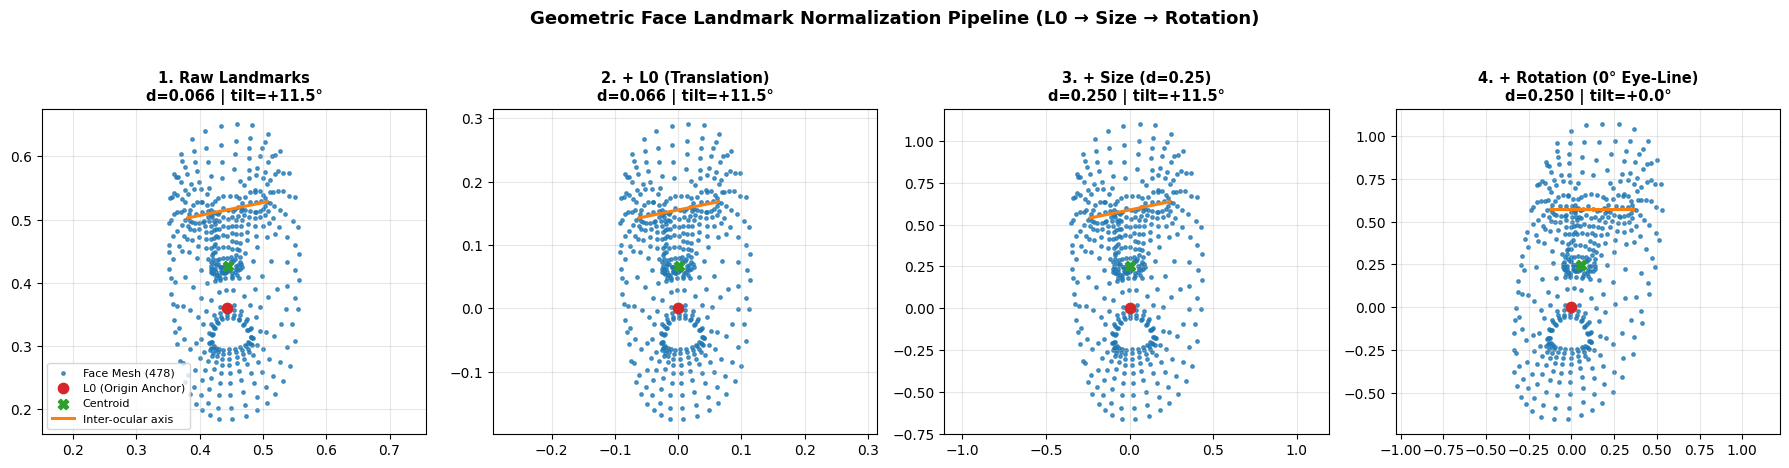

In [46]:
# Visualize the step-by-step effect of L0, size, and rotation normalization on a sample face
sample_idx = 0
plot_normalization_stages(raw_train_data[sample_idx], target_dist=0.25)

### Common training parameters
Execute only once, do not execute with each network change!!!!!!!!

In [47]:
# Parameters
np.random.seed(2022)
num_channels = 42
batch_size = 8
epochs = 300
dropout = 0.3
num_cnn_features = 64
patience = 50 # Número de épocas sin mejora antes de detener el entrenamiento
k = 10

# List where to save the results you want to display to compare metrics
model_results = []

## Training the model

Execute once for each change in the type of network.

#### 🔹 Optimizer Comparison in Keras

| **Optimizer** | **Recommended for** | **Suggested Initial Learning Rate** | **Usage Code** |
|--------------|---------------------|----------------------------------|--------------|
| **Adam** (🔥 Best general choice) | Complex models, large datasets, CNNs, and MLPs | `0.001` | `Adam(learning_rate=0.001)` |
| **RMSprop** | Sequential data, RNNs/LSTMs, unstable gradients | `0.0005` | `RMSprop(learning_rate=0.0005)` |
| **SGD with momentum** | Models that need better generalization | `0.01` | `SGD(learning_rate=0.01, momentum=0.9)` |
| **AdamW** | Deep networks, noisy datasets, overfitting issues | `0.001`, with `weight_decay=1e-4` | `AdamW(learning_rate=0.001, weight_decay=1e-4)` |


In [48]:
import time
import keras
import time
import numpy as np
from keras.models import Sequential, Model
from keras.layers import Input, Dense, Dropout, Activation, Flatten
from keras.layers import Conv2D, Conv3D, MaxPooling2D, MaxPooling3D, Reshape
from keras.layers import LSTM, SimpleRNN, GRU, BatchNormalization
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, roc_curve, auc
from keras.optimizers import AdamW
from keras.callbacks import EarlyStopping
from models.VIT import mlp, Patches, PatchEncoder
from models.models import define_network_model
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, roc_curve, auc
from keras.optimizers import AdamW
from keras.callbacks import EarlyStopping

print('\n[DefineNetworkModel]')

# Types: "CNN, VIT, TL (Transfer Learning)"
network_type = "CNN"
#network_type = "VIT"

# Everything is referred to 'data_path' which was originally set to 'new_dataset_path'
models_folder = data_path + '/' + 'models/'

# In case of using fine-tunning load weights of the trained model with CNN1
load_model = models_path + r'poses.h5'

num_channels = 1
learning_rate=0.001

pretrained_model_path = os.path.join(models_folder, "cnn_size.keras")

model = define_network_model(num_classes = num_classes,
                             network_type = network_type,
                             num_cnn_features = num_cnn_features,
                             pretrained_model_path = pretrained_model_path,
                             dropout = dropout)

# Definir el criterio de parada temprana
early_stopping = EarlyStopping(
    monitor='val_loss',  # Puedes cambiarlo a 'val_accuracy' si prefieres
    patience=patience,          # Número de épocas sin mejora antes de detener el entrenamiento
    restore_best_weights=True,  # Restaurar los mejores pesos del modelo
    verbose=1
)

# opt=tf.keras.optimizers.SGD(lr=0.001)
# opt=tf.keras.optimizers.RMSprop(lr=0.0005, rho=0.9, epsilon=1e-08, decay=0.0)
opt = AdamW(learning_rate=0.0001, weight_decay=1e-4)  # Ajusta el weight decay según el problema
model.compile(loss='categorical_crossentropy', optimizer=opt, metrics=['accuracy'])

print('\n[model.fit][Training starts!]\n')
start_time = time.time()

# Training with Early Stopping
history = model.fit(x_train,
                    y_train_data_format,
                    batch_size=batch_size,
                    epochs=epochs,
                    verbose=1,
                    shuffle=True,
                    validation_data=(x_test, y_test_data_format),  # Asegúrate de tener datos de validación
                    callbacks=[early_stopping])

end_time = time.time()
execution_time = end_time - start_time
print(f"\nTraining finished, execution time: {execution_time:.2f} s")


[DefineNetworkModel]
Model creation:
	network_type = CNN
	num_classes = 4
	dropout = 0.3
	num_cnn_features = 64

[MODEL SUMMARY]


Model: "CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                ┃ Output Shape          ┃    Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ conv2d (Conv2D)             │ (None, 478, 2, 64)    │     25,664 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ max_pooling2d               │ (None, 120, 2, 64)    │          0 │   -   │
│ (MaxPooling2D)              │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dropout (Dropout)           │ (None, 120, 2, 64)    │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ conv2d_1 (Conv2D)           │ (None, 120, 2, 64)    │    491,584 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ max_pooling2d_1             │ (None, 30, 2, 64)     │          0 │   -   │
│ (MaxPooling2D)              │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dropout_1 (Dropout)         │ (None, 30, 2, 64)     │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ conv2d_2 (Conv2D)           │ (None, 30, 2, 64)     │     81,984 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dropout_2 (Dropout)         │ (None, 30, 2, 64)     │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ flatten (Flatten)           │ (None, 3840)          │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dense (Dense)               │ (None, 128)           │    491,648 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dropout_3 (Dropout)         │ (None, 128)           │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dense_1 (Dense)             │ (None, 4)             │        516 │   Y   │
└─────────────────────────────┴───────────────────────┴────────────┴───────┘

 Total params: 1,091,396 (4.16 MB)

 Trainable params: 1,091,396 (4.16 MB)

 Non-trainable params: 0 (0.00 B)


[model.fit][Training starts!]

Epoch 1/300
21/21 ━━━━━━━━━━━━━━━━━━━━ 14s 105ms/step - accuracy: 0.2440 - loss: 1.4050 - val_accuracy: 0.2500 - val_loss: 1.3830
Epoch 2/300
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.2738 - loss: 1.3826 - val_accuracy: 0.2500 - val_loss: 1.3806
Epoch 3/300
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.2917 - loss: 1.3861 - val_accuracy: 0.4583 - val_loss: 1.3767
Epoch 4/300
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.2917 - loss: 1.3811 - val_accuracy: 0.4028 - val_loss: 1.3740
Epoch 5/300
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.2440 - loss: 1.3786 - val_accuracy: 0.2778 - val_loss: 1.3683
Epoch 6/300
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.2976 - loss: 1.3637 - val_accuracy: 0.2500 - val_loss: 1.3599
Epoch 7/300
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.2440 - loss: 1.3663 - val_accuracy: 0.4167 - val_loss: 1.3531
Epoch 8/300
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.3155 - 

#### Visualizing the training results

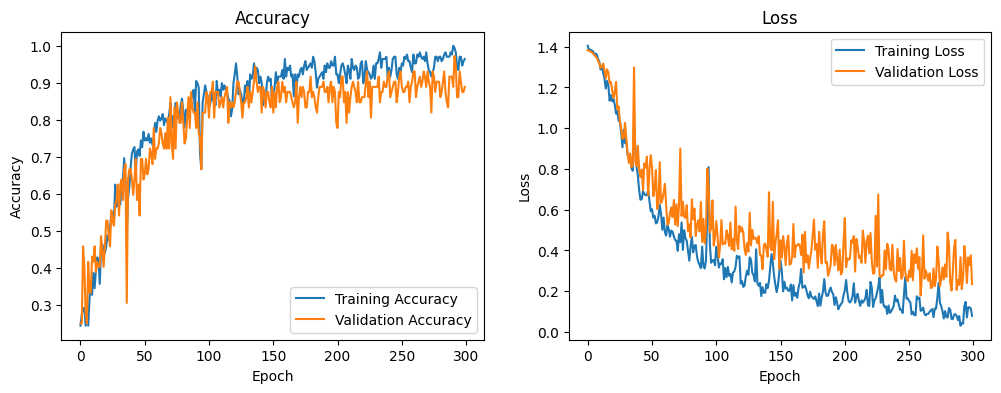

In [49]:
# prompt: plot learning curves

import matplotlib.pyplot as plt

# Assuming 'history' is the output of model.fit
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

### Performance analysis

In [50]:
print('[SETUP]')
print('\t[Normalization: %s]' % normalization)
print('\t[Type of network: %s]' % network_type)
print('\t[Num classes: %d]' % num_classes)

# For train data
predictions = model.predict(x_train, batch_size = batch_size, verbose = 1)
y_pred_train = np.argmax(predictions, axis=1)
y_true_train = np.argmax(y_train_data_format, axis=1)
print('y_pred_train', y_pred_train)
print('y_true_train', y_true_train)
matrix = confusion_matrix(y_true_train, y_pred_train) #, labels=np.arange(1, num_classes + 1))

print('[Number of training examples = %d]' % matrix.sum())
print('\n[Confusion matrix for training data]')
print(matrix)
print('\n[Train accuracy = %0.4f]' % accuracy_score(y_true_train, y_pred_train))
print('[Train unweighted f-measure = %0.4f]' % f1_score(y_true_train, y_pred_train, average='macro'))
print('[Train weighted f-measure = %0.4f]' % f1_score(y_true_train, y_pred_train, average='weighted'))

# For test data
prediction = model.predict(x = x_test, batch_size = batch_size, verbose = 1)
y_pred_test = np.argmax(prediction, axis=1)
y_true_test = np.argmax(y_test_data_format, axis=1)
print('y_pred_test', y_pred_test)
print('y_true_test', y_true_test)
matrix = confusion_matrix(y_true_test, y_pred_test) #, labels=np.arange(1, num_classes+1))

print('[Number of test examples = %d]' % matrix.sum())
print('\n[Confusion matrix for test data]')
print(matrix)
print('\n[Test accuracy = %0.4f]' % accuracy_score(y_true_test, y_pred_test))
print('[Test unweighted f-measure = %0.4f]' % f1_score(y_true_test, y_pred_test, average='macro'))
print('[Test weighted f-measure = %0.4f]' % f1_score(y_true_test, y_pred_test, average='weighted'))

end_time = time.time()
execution_time = end_time - start_time

model_results.append({
    "model_type": network_type,
    "normalization": normalization,
    "accuracy": accuracy_score(y_true_test, y_pred_test),
    "f-measure_unweighted": f1_score(y_true_test, y_pred_test, average='macro'),
    "f-measure_weighted": f1_score(y_true_test, y_pred_test, average='weighted'),
    "execution_time": execution_time
  })


[SETUP]
	[Normalization: ['L0', 'size', 'rotation']]
	[Type of network: CNN]
	[Num classes: 4]
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
y_pred_train [3 0 1 0 0 1 0 2 1 1 0 0 3 3 1 3 1 0 2 1 1 1 3 2 3 2 2 3 0 2 0 2 2 1 3 0 0
 0 1 2 1 3 1 1 3 0 0 1 3 1 1 1 2 2 0 0 0 1 2 3 3 2 3 2 3 1 2 2 1 0 0 3 3 1
 0 1 1 2 0 2 0 3 2 3 1 3 3 0 3 0 2 1 0 2 0 1 1 1 1 0 2 0 3 3 2 0 0 1 1 0 3
 2 3 2 1 2 2 2 3 3 3 0 2 2 0 2 1 1 0 1 2 2 0 0 3 2 2 1 0 3 0 3 3 2 0 2 3 2
 0 1 0 3 3 3 2 3 2 0 1 2 3 0 3 1 3 2 1 3]
y_true_train [3 0 1 0 0 1 0 2 1 1 0 0 3 3 1 3 1 0 2 1 1 1 3 2 3 2 2 3 0 2 0 2 2 1 3 0 0
 0 1 2 1 3 1 1 3 0 0 1 3 1 1 1 2 2 0 0 0 1 2 3 3 2 3 2 3 1 2 2 1 0 0 3 3 1
 0 1 1 2 0 2 0 3 2 3 1 3 3 0 3 0 2 1 0 2 0 1 1 1 1 0 2 0 3 3 2 0 0 1 1 0 3
 2 3 2 1 2 2 2 3 3 3 0 2 2 0 2 1 1 0 1 2 2 0 0 3 2 2 1 0 3 1 3 3 2 0 2 3 2
 0 1 0 3 3 3 2 3 2 0 1 2 3 0 3 1 3 2 1 3]
[Number of training examples = 168]

[Confusion matrix for training data]
[[42  0  0  0]
 [ 1 41  0  0]
 [ 0  0 42  0]
 [ 0  0  0 42]]

[Train accuracy = 0.

### Model Saving
To save data in your Collab in folder 'models'.

In [51]:
# First we serialize model to JSON
model_json = model.to_json()

# Second we check whether folder for models exists or not
if not os.path.exists(models_path):
    os.makedirs(models_path)

# Third we define the root filename which will be used when creating the model files
root_filename = 'new_model'

aux = ''
if normalization:
  if 'L0' in normalization:
    aux += '_L0'
  if 'size' in normalization:
    aux += '_size'
  if 'rotation' in normalization:
    aux += '_rotation'

# Fourth we save the model description
json_filename = os.path.join(models_path, f"{root_filename}_{network_type}{aux}.json")
print(f'[SAVING MODEL DESCRIPTION][{json_filename}]')
with open(json_filename, 'w') as json_file:
    json_file.write(model_json)

# Save model using the recommended Keras 3 format
keras_filename = os.path.join(models_path, f"{root_filename}_{network_type}{aux}.keras")
print(f'[SAVING MODEL][{keras_filename}]')
model.save(keras_filename)

print('[MODEL SAVED!!!]')

[SAVING MODEL DESCRIPTION][/content/IE-workspace/FER_mediapipe/models/new_model_CNN_L0_size_rotation.json]
[SAVING MODEL][/content/IE-workspace/FER_mediapipe/models/new_model_CNN_L0_size_rotation.keras]
[MODEL SAVED!!!]


## Ablation Study: Assessing the Importance of Landmark Normalizations

To scientifically evaluate why landmark normalization is critical for real-time deployment on the Raspberry Pi, the cell below runs a controlled **ablation experiment** comparing 5 configurations of the network:
1. **No Normalization (`[]`)**: Raw image coordinates $(x, y)$ directly from MediaPipe.
2. **Translation Only (`['L0']`)**: Invariant to 2D position in the frame, but still sensitive to distance and head tilt.
3. **Translation + Size (`['L0', 'size']`)**: Invariant to position and camera distance, but still sensitive to in-plane head rotation.
4. **Translation + Rotation (`['L0', 'rotation']`)**: Invariant to position and head tilt, but still sensitive to camera distance.
5. **Full Normalization (`['L0', 'size', 'rotation']`)**: Invariant to position, face size / camera distance, and head rotation.

Each trained model is evaluated on both the **Standard Test Set** and a **Geometrically Perturbed Test Set** (which simulates a real user moving closer/farther $\times [0.55, 1.65]$, shifting in the camera frame $\pm 0.25$, and tilting their head $\pm 35^\circ$).


[ABLATION EXPERIMENT] 1. No Normalization ([]) | normalizations = []
Model creation:
	network_type = CNN
	num_classes = 4
	dropout = 0.3
	num_cnn_features = 64

[MODEL SUMMARY]


Model: "CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                ┃ Output Shape          ┃    Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ conv2d_3 (Conv2D)           │ (None, 478, 2, 64)    │     25,664 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ max_pooling2d_2             │ (None, 120, 2, 64)    │          0 │   -   │
│ (MaxPooling2D)              │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dropout_4 (Dropout)         │ (None, 120, 2, 64)    │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ conv2d_4 (Conv2D)           │ (None, 120, 2, 64)    │    491,584 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ max_pooling2d_3             │ (None, 30, 2, 64)     │          0 │   -   │
│ (MaxPooling2D)              │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dropout_5 (Dropout)         │ (None, 30, 2, 64)     │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ conv2d_5 (Conv2D)           │ (None, 30, 2, 64)     │     81,984 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dropout_6 (Dropout)         │ (None, 30, 2, 64)     │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ flatten_1 (Flatten)         │ (None, 3840)          │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dense_2 (Dense)             │ (None, 128)           │    491,648 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dropout_7 (Dropout)         │ (None, 128)           │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dense_3 (Dense)             │ (None, 4)             │        516 │   Y   │
└─────────────────────────────┴───────────────────────┴────────────┴───────┘

 Total params: 1,091,396 (4.16 MB)

 Trainable params: 1,091,396 (4.16 MB)

 Non-trainable params: 0 (0.00 B)

... (21 outputs left out)

 Total params: 1,091,396 (4.16 MB)

 Trainable params: 1,091,396 (4.16 MB)

 Non-trainable params: 0 (0.00 B)

  -> Standard Test Acc :  79.17% (Macro-F1:  79.19%)
  -> Perturbed Test Acc:  79.17% (Macro-F1:  79.19%) [Simulated distance/shift/rotation variations]

================ ABLATION STUDY SUMMARY ================
                                 Configuration             Normalizations  Standard Test Acc (%)  Standard Macro-F1 (%)  Perturbed Test Acc (%)  Perturbed Macro-F1 (%)  Training Time (s)
                      1. No Normalization ([])                         []                  25.00                  10.00                   16.67                   12.74              11.57
                  2. Translation Only (['L0'])                     ['L0']                  66.67                  66.71                   43.06                   41.03              26.61
        3. Translation + Size (['L0', 'size'])             ['L0', 'size']                  76.39                  76.54                   59.72                   58.25              26.24
4. Translation + Rotation (['L0', 'rotati

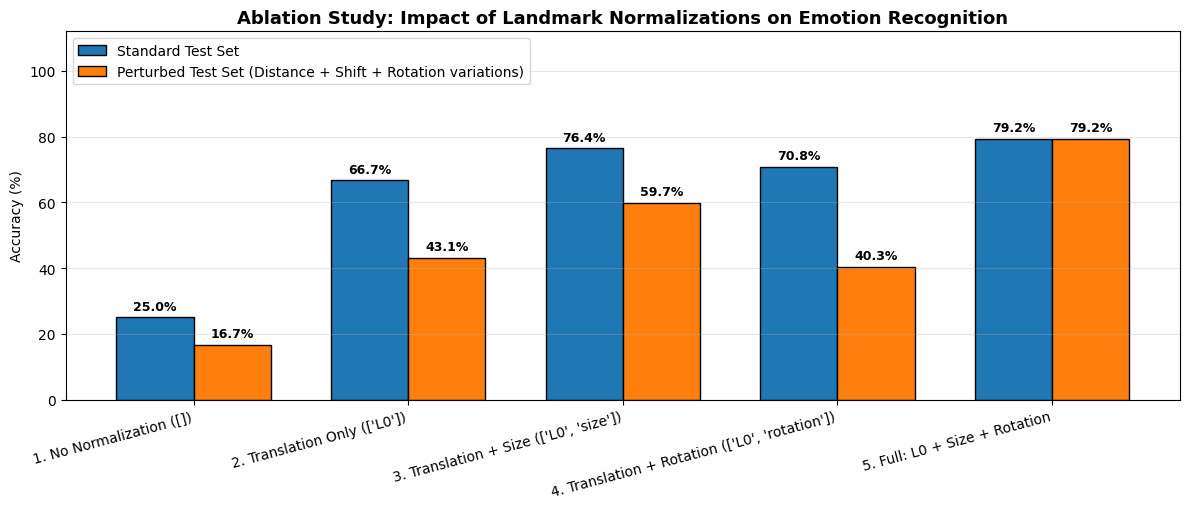

,Configuration,Normalizations,Standard Test Acc (%),Standard Macro-F1 (%),Perturbed Test Acc (%),Perturbed Macro-F1 (%),Training Time (s)
0,1. No Normalization ([]),[],25.00,10.00,16.67,12.74,11.57
1,2. Translation Only (['L0']),['L0'],66.67,66.71,43.06,41.03,26.61
2,"3. Translation + Size (['L0', 'size'])","['L0', 'size']",76.39,76.54,59.72,58.25,26.24
3,"4. Translation + Rotation (['L0', 'rotation'])","['L0', 'rotation']",70.83,70.06,40.28,38.27,26.48
4,5. Full: L0 + Size + Rotation,"['L0', 'size', 'rotation']",79.17,79.19,79.17,79.19,27.75


In [52]:
from landmarks_utils import run_normalization_ablation_study

df_ablation_results = run_normalization_ablation_study(
    raw_train_data=raw_train_data,
    y_train_onehot=y_train_data_format,
    raw_test_data=raw_test_data,
    y_test_onehot=y_test_data_format,
    define_network_model_fn=define_network_model,
    num_classes=num_classes,
    network_type=network_type,
    num_cnn_features=num_cnn_features,
    dropout=dropout,
    batch_size=batch_size,
    epochs=80,
    patience=20,
)
df_ablation_results

## Save model results

In [53]:
model_results

[{'model_type': 'CNN',
  'normalization': ['L0', 'size', 'rotation'],
  'accuracy': 0.9305555555555556,
  'f-measure_unweighted': 0.9313940960999785,
  'f-measure_weighted': 0.9313940960999785,
  'execution_time': 106.4853925704956}]

In [54]:
# Everything is referred to 'data_path' which was originally set to 'new_dataset_path'
results_folder = data_path + '/' + 'results/'

# Second we check whether folder for models exists or not
if not os.path.exists(results_folder):
    os.makedirs(results_folder)

filename = results_folder + '/results.txt'
print('[SAVING RESULTS][%s]' % filename)

# To execute after training the 4 models.
with open(filename, 'a') as f:
    f.write(f"Model Type: {network_type}\n")
    f.write(f"Normalization: {normalization}\n")
    f.write(f"Accuracy: {model_results[-1]['accuracy']}\n")
    f.write(f"F-measure (Unweighted): {model_results[-1]['f-measure_unweighted']}\n")
    f.write(f"F-measure (Weighted): {model_results[-1]['f-measure_weighted']}\n")
    f.write(f"Execution Time: {model_results[-1]['execution_time']} seconds\n")
    f.write("\n")


[SAVING RESULTS][/content/drive/MyDrive/FER_mediapipe/data/my_faces_dataset//results//results.txt]


# Systems Comparison


In this last section, we will compare results obtained from our trained models.


Comparing models is a common practice in the field of machine learning and data science to determine which model provides the best performance for a particular problem. When comparing models, the goal is to identify which one is capable of making more accurate and generalizable predictions.

When comparing models, it is important to consider the number of samples you are working with. The sample size can have a significant impact on the performance of the models and the reliability of the evaluation metrics. Depending on whether you have used cross-validation or split the data into train and test sets.

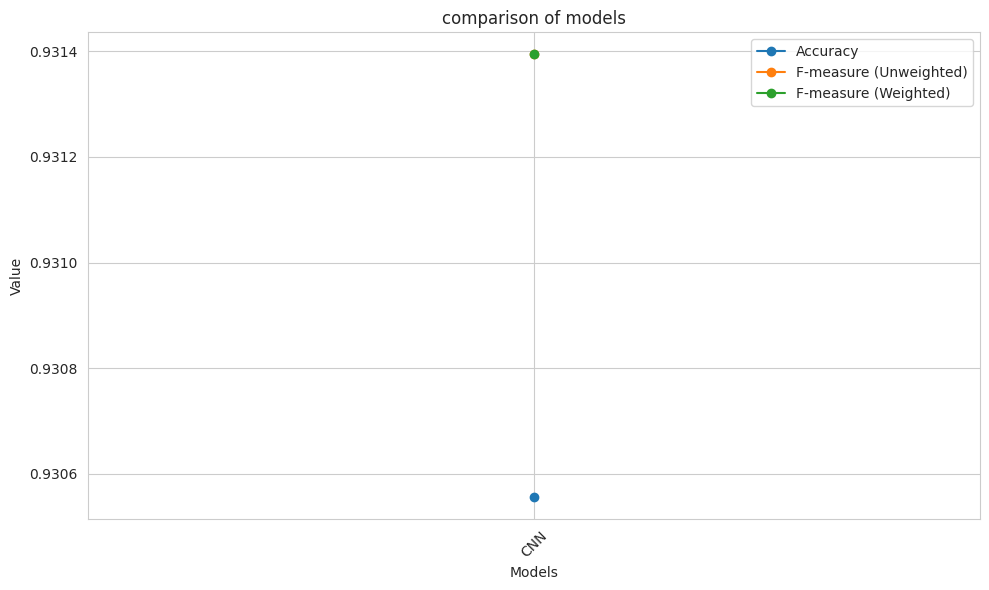

In [55]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")  # Seaborn way of setting style

# Compare accuracy and f-score
model_types = [result['model_type'] for result in model_results]
accuracies = [result['accuracy'] for result in model_results]
fmeasure_unweighted = [result['f-measure_unweighted'] for result in model_results]
fmeasure_weighted = [result['f-measure_weighted'] for result in model_results]

fig, ax = plt.subplots(figsize=(10, 6))

x = range(len(model_types))

# Accuracy (accuracy)
ax.plot(x, accuracies, marker='o', label='Accuracy')

# F-score  (unweighted fmeasure)
ax.plot(x, fmeasure_unweighted, marker='o', label='F-measure (Unweighted)')

# F-score  (weighted fmeasure)
ax.plot(x, fmeasure_weighted, marker='o', label='F-measure (Weighted)')

ax.set_xticks(x)
ax.set_xticklabels(model_types, rotation=45)

ax.set_title('comparison of models')
ax.set_xlabel('Models')
ax.set_ylabel('Value')

ax.legend()
plt.tight_layout()
plt.show()

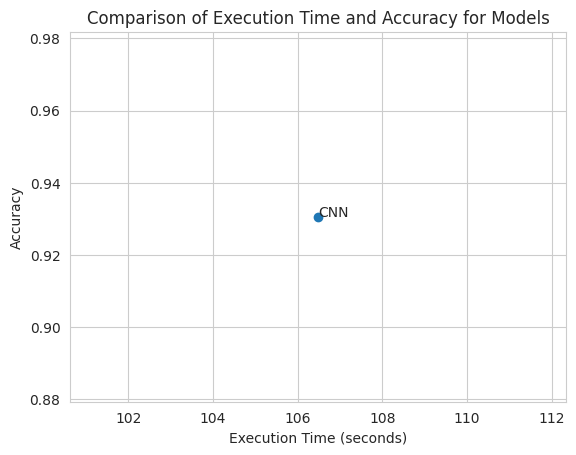

In [56]:
import matplotlib.pyplot as plt

execution_times = [result['execution_time'] for result in model_results]
accuracies = [result['accuracy'] for result in model_results]
model_types = [result['model_type'] for result in model_results]

# Create scatter plot
plt.scatter(execution_times, accuracies)

# Label each point with the model type
for i, model_type in enumerate(model_types):
    plt.annotate(model_type, (execution_times[i], accuracies[i]))

# Axis labels
plt.xlabel('Execution Time (seconds)')
plt.ylabel('Accuracy')

# Plot title
plt.title('Comparison of Execution Time and Accuracy for Models')

# Show the plot
plt.show()

### Run only when evaluating with the CNN option

In [57]:
# USING CONFIDENCE INTERVALS
from evaluation import CalculateCI, find_best_result

num_samples = test_data.shape[0]

"""
num_samples is the amount of test data if we use split into  train - test and
we use the total amount of data if we use cross validation
"""

model_type_to_search = 'CNN'
best_index = find_best_result(model_type_to_search, model_results)

if best_index is not None:
    print(f"The best result for model type '{model_type_to_search}' is at index {best_index}.")
    print(model_results[best_index])
else:
    print(f"No results found for model type '{model_type_to_search}'.")

acc_CNN = 100*model_results[best_index]['accuracy']
CI_cnn = CalculateCI(num_samples, acc_cnn)
print('[cnn][accuracy = %0.2f (%0.2f, %0.2f)]' % (acc_cnn, acc_cnn-CI_cnn, acc_cnn+CI_cnn))

The best result for model type 'CNN' is at index 0.
{'model_type': 'CNN', 'normalization': ['L0', 'size', 'rotation'], 'accuracy': 0.9305555555555556, 'f-measure_unweighted': 0.9313940960999785, 'f-measure_weighted': 0.9313940960999785, 'execution_time': 106.4853925704956}


NameError: name 'acc_cnn' is not defined

### Run only when evaluating with the VIT option

In [58]:
model_type_to_search = 'VIT'
best_index = find_best_result(model_type_to_search, model_results)

if best_index is not None:
    print(f"The best result for model type '{model_type_to_search}' is at index {best_index}.")
    print(model_results[best_index])
else:
    print(f"No results found for model type '{model_type_to_search}'.")

acc_vit = 100*model_results[best_index]['accuracy']
CI_VIT = CalculateCI(num_samples, acc_vit)
print('[CNN2][accuracy = %0.2f (%0.2f, %0.2f)]' % (acc_vit, acc_vit-CI_VIT, acc_vit+CI_VIT))

No results found for model type 'VIT'.


TypeError: list indices must be integers or slices, not NoneType

### Run only when evaluating with the FINE-TUNNING option

In [59]:
model_type_to_search = 'FINE-TUNING'
best_index = find_best_result(model_type_to_search, model_results)

if best_index is not None:
    print(f"The best result for model type '{model_type_to_search}' is at index {best_index}.")
    print(model_results[best_index])
else:
    print(f"No results found for model type '{model_type_to_search}'.")

acc_fine_tunning1 = 100*model_results[best_index]['accuracy']
CI_fine_tunning1 = CalculateCI(num_samples, acc_fine_tunning1)
print('[FINE-TUNING1][accuracy = %0.2f (%0.2f, %0.2f)]' % (acc_fine_tunning1, acc_fine_tunning1-CI_fine_tunning1, acc_fine_tunning1+CI_fine_tunning1))

No results found for model type 'FINE-TUNING'.


TypeError: list indices must be integers or slices, not NoneType

## Final plot

In [60]:
# PLOT RESULTS
import matplotlib.pyplot as plt
import numpy as np

# ARRAYS/INFO TO PLOT
means = [acc_cnn]
CI = [CI_cnn]
model_labels = ['CNN']

# WITH FINETUNED MODELS
#means = [acc_cnn, acc_VIT, acc_fine_tunning]
#CI = [CI_cnn, CI_VIT, CI_fine_tunning]
#model_labels = ['CNN', 'VIT', 'FINE-TUNING']


# PLOT DATA
fig, ax = plt.subplots(1)
plt.errorbar([0], [acc_cnn], yerr=[CI_cnn], fmt='o', label='CNN', color="blue")
#plt.errorbar([1], [acc_VIT], yerr=[CI_VIT], fmt='o', label='VIT', color="red")
#plt.errorbar([2], [acc_fine_tunning], yerr=[CI_fine_tunning], fmt='o', label='FINE-TUNNING', color="green")

#PLOT FORMAT
#plt.xlim(-0.5, 3.5)
plt.legend(loc='lower right')
plt.ylabel('Accuracy ± CI (%)')
plt.xlabel('Models')
plt.xticks(range(len(model_labels)), model_labels)

plt.show()

NameError: name 'acc_cnn' is not defined